In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Identificar a raiz do projeto
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Diretório dos dados
DATA_DIR = PROJECT_DIR / "data" / "raw"

# Verificar arquivos
files = sorted(DATA_DIR.glob("*.csv"))

print("Arquivos encontrados:", len(files))

for file in files:
    print(file.name)

Arquivos encontrados: 3
gender_submission.csv
test.csv
train.csv


In [3]:
# Carregar os dados de treinamento
train = pd.read_csv(DATA_DIR / "train.csv")

# Carregar os dados de teste
test = pd.read_csv(DATA_DIR / "test.csv")

# Carregar exemplo de submissão
gender_submission = pd.read_csv(
    DATA_DIR / "gender_submission.csv"
)

print("Datasets carregados!")

Datasets carregados!


In [4]:
print("Dimensões do treinamento:")
print(train.shape)

print("\nDimensões do teste:")
print(test.shape)

print("\nPrimeiros registros:")
display(train.head())

Dimensões do treinamento:
(891, 12)

Dimensões do teste:
(418, 11)

Primeiros registros:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("Informações do treinamento:")

train.info()

print("\nValores ausentes:")

display(
    train.isnull().sum().sort_values(
        ascending=False
    )
)

Informações do treinamento:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Valores ausentes:


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

In [6]:
print("Distribuição da sobrevivência:")

display(train["Survived"].value_counts())

print("\nPercentuais:")

display(
    train["Survived"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Distribuição da sobrevivência:


Survived
0    549
1    342
Name: count, dtype: int64


Percentuais:


Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

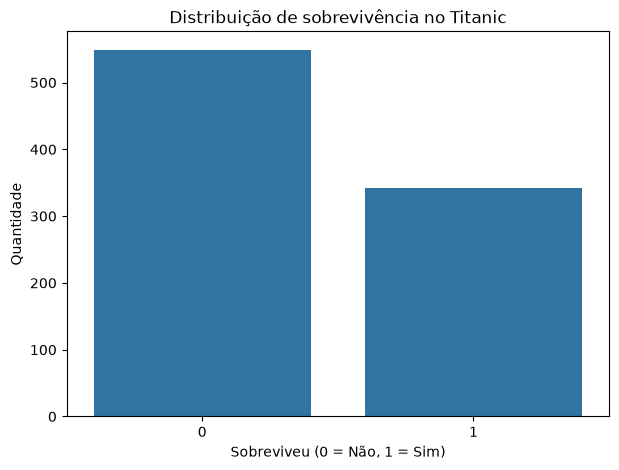

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x="Survived"
)

plt.title("Distribuição de sobrevivência no Titanic")
plt.xlabel("Sobreviveu (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade")

plt.show()

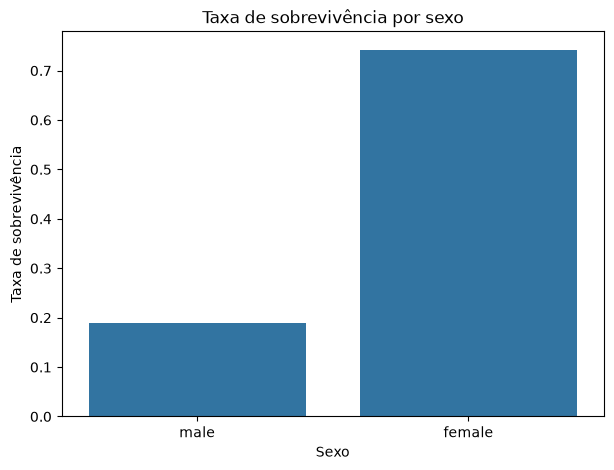

In [8]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=train,
    x="Sex",
    y="Survived",
    errorbar=None
)

plt.title("Taxa de sobrevivência por sexo")
plt.xlabel("Sexo")
plt.ylabel("Taxa de sobrevivência")
plt.show()

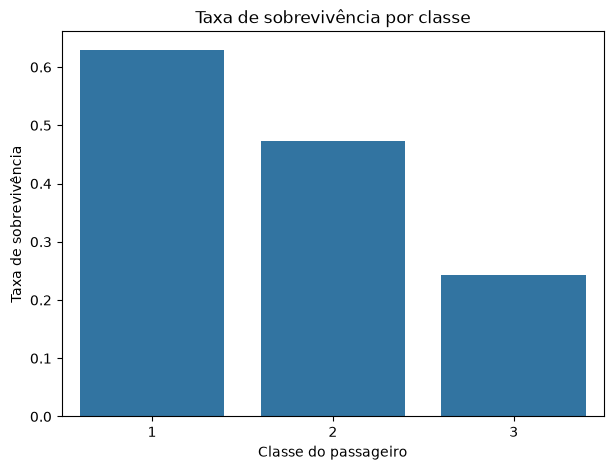

In [9]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=train,
    x="Pclass",
    y="Survived",
    errorbar=None
)

plt.title("Taxa de sobrevivência por classe")
plt.xlabel("Classe do passageiro")
plt.ylabel("Taxa de sobrevivência")
plt.show()

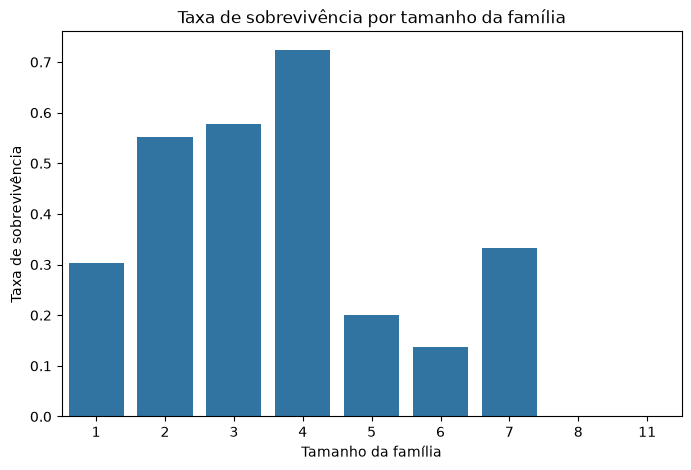

In [10]:
train_eda = train.copy()

train_eda["FamilySize"] = (
    train_eda["SibSp"] +
    train_eda["Parch"] + 1
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=train_eda,
    x="FamilySize",
    y="Survived",
    errorbar=None
)

plt.title("Taxa de sobrevivência por tamanho da família")
plt.xlabel("Tamanho da família")
plt.ylabel("Taxa de sobrevivência")
plt.show()

In [11]:
print("Sobrevivência por sexo:")
display(
    pd.crosstab(
        train["Sex"],
        train["Survived"],
        normalize="index"
    ).round(3) * 100
)

print("Sobrevivência por classe:")
display(
    pd.crosstab(
        train["Pclass"],
        train["Survived"],
        normalize="index"
    ).round(3) * 100
)

print("Sobrevivência por local de embarque:")
display(
    pd.crosstab(
        train["Embarked"],
        train["Survived"],
        normalize="index"
    ).round(3) * 100
)

Sobrevivência por sexo:


Survived,0,1
Sex,,
female,25.8,74.2
male,81.1,18.9


Sobrevivência por classe:


Survived,0,1
Pclass,,
1,37.0,63.0
2,52.7,47.3
3,75.8,24.2


Sobrevivência por local de embarque:


Survived,0,1
Embarked,,
C,44.6,55.4
Q,61.0,39.0
S,66.3,33.7


In [12]:
family_summary = (
    train_eda.groupby("FamilySize")["Survived"]
    .agg(
        passageiros="count",
        sobreviventes="sum",
        taxa_sobrevivencia="mean"
    )
)

family_summary["taxa_sobrevivencia"] *= 100

display(family_summary.round(2))

,passageiros,sobreviventes,taxa_sobrevivencia
FamilySize,,,
1,537,163,30.35
2,161,89,55.28
3,102,59,57.84
4,29,21,72.41
5,15,3,20.00
6,22,3,13.64
7,12,4,33.33
8,6,0,0.00
11,7,0,0.00


In [13]:
def create_features(df):
    df = df.copy()

    # Tamanho da família
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # Passageiro viajando sozinho
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # Existência de cabine registrada
    df["HasCabin"] = df["Cabin"].notna().astype(int)

    # Extração do tratamento do nome
    df["Title"] = df["Name"].str.extract(
        r",\s*([^.]*)\.",
        expand=False
    )

    # Agrupamento de títulos semelhantes
    df["Title"] = df["Title"].replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })

    # Agrupamento de títulos raros
    rare_titles = [
        "Don", "Rev", "Dr", "Major", "Lady",
        "Sir", "Col", "Capt", "Countess",
        "Jonkheer", "Dona"
    ]

    df["Title"] = df["Title"].replace(
        rare_titles,
        "Rare"
    )

    return df


train_ml = create_features(train)
test_ml = create_features(test)

display(
    train_ml[[
        "Name", "Title", "FamilySize",
        "IsAlone", "HasCabin"
    ]].head(10)
)

,Name,Title,FamilySize,IsAlone,HasCabin
0,"Braund, Mr. Owen Harris",Mr,2,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,1
2,"Heikkinen, Miss. Laina",Miss,1,1,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,1
4,"Allen, Mr. William Henry",Mr,1,1,0
5,"Moran, Mr. James",Mr,1,1,0
6,"McCarthy, Mr. Timothy J",Mr,1,1,1
7,"Palsson, Master. Gosta Leonard",Master,5,0,0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs,3,0,0
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs,2,0,0


In [14]:
from sklearn.model_selection import train_test_split

X = train_ml.drop(
    columns=[
        "Survived", "PassengerId",
        "Name", "Ticket", "Cabin"
    ]
)

y = train_ml["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)

print("\nDistribuição do treinamento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribuição da validação:")
print(y_val.value_counts(normalize=True).round(3))

Treinamento: (712, 11)
Validação: (179, 11)

Distribuição do treinamento:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Distribuição da validação:
Survived
0    0.615
1    0.385
Name: proportion, dtype: float64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Variáveis numéricas
numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone",
    "HasCabin"
]

# Variáveis categóricas
categorical_features = [
    "Sex",
    "Embarked",
    "Title"
]

# Preparação das variáveis numéricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preparação das variáveis categóricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinação dos tratamentos
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Pipeline completo
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Treinamento
model.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_val)

print("Resultados da validação:\n")

print("Acurácia:", round(accuracy_score(y_val, y_pred), 4))
print("Precisão:", round(precision_score(y_val, y_pred), 4))
print("Recall:", round(recall_score(y_val, y_pred), 4))
print("F1-score:", round(f1_score(y_val, y_pred), 4))

print("\nRelatório de classificação:")
print(classification_report(y_val, y_pred))

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_pred))

Resultados da validação:

Acurácia: 0.8324
Precisão: 0.8
Recall: 0.7536
F1-score: 0.7761

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       110
           1       0.80      0.75      0.78        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179


Matriz de confusão:
[[97 13]
 [17 52]]


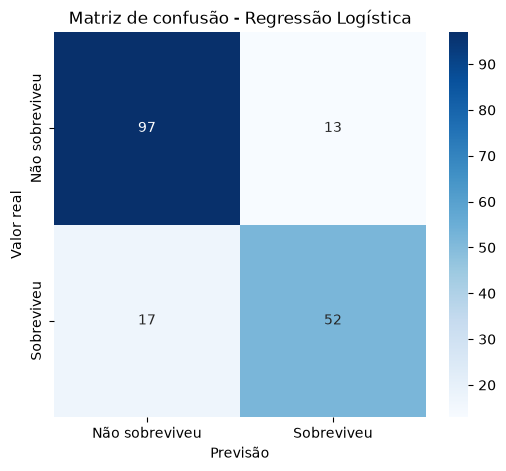

In [17]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_val, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Não sobreviveu", "Sobreviveu"],
    yticklabels=["Não sobreviveu", "Sobreviveu"]
)

plt.title("Matriz de confusão - Regressão Logística")
plt.xlabel("Previsão")
plt.ylabel("Valor real")
plt.show()

In [18]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

# Modelos que serão comparados
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),

    "SVM": SVC(
        C=1.0,
        kernel="rbf"
    )
}

# Validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métricas da comparação
scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Modelos preparados para comparação!")

Modelos preparados para comparação!


In [19]:
cv_results = []

for name, classifier in candidates.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Modelo": name,
        "Acurácia média": scores["test_accuracy"].mean(),
        "Acurácia desvio": scores["test_accuracy"].std(),
        "F1 médio": scores["test_f1"].mean(),
        "ROC-AUC médio": scores["test_roc_auc"].mean()
    })

comparison = pd.DataFrame(cv_results)

comparison = comparison.sort_values(
    by="Acurácia média",
    ascending=False
)

display(comparison.round(4))

,Modelo,Acurácia média,Acurácia desvio,F1 médio,ROC-AUC médio
0,Logistic Regression,0.8259,0.0298,0.7728,0.8716
2,Extra Trees,0.8259,0.0238,0.7566,0.8804
3,SVM,0.8259,0.0172,0.7625,0.8642
1,Random Forest,0.8231,0.0224,0.7583,0.8869


In [20]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Treinar com todos os dados disponíveis
final_model.fit(X, y)

print("Modelo definitivo treinado!")
print("Quantidade de passageiros:", len(X))
print("Quantidade de variáveis:", X.shape[1])

Modelo definitivo treinado!
Quantidade de passageiros: 891
Quantidade de variáveis: 11


In [21]:
# Preparar os dados de teste
X_test = test_ml.drop(
    columns=[
        "PassengerId",
        "Name",
        "Ticket",
        "Cabin"
    ]
)

# Prever sobrevivência
test_predictions = final_model.predict(X_test)

print("Previsões realizadas!")
print("Total de previsões:", len(test_predictions))

print("\nDistribuição das previsões:")
print(pd.Series(test_predictions).value_counts())

Previsões realizadas!
Total de previsões: 418

Distribuição das previsões:
0    252
1    166
Name: count, dtype: int64


In [22]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

SUBMISSION_DIR = PROJECT_DIR / "submissions"
MODELS_DIR = PROJECT_DIR / "models"

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

submission = pd.DataFrame({
    "PassengerId": test_ml["PassengerId"],
    "Survived": test_predictions.astype(int)
})

# Conferir o formato
assert len(submission) == 418
assert list(submission.columns) == ["PassengerId", "Survived"]
assert submission["Survived"].isin([0, 1]).all()

# Salvar CSV
submission_path = SUBMISSION_DIR / "submission.csv"

submission.to_csv(
    submission_path,
    index=False
)

display(submission.head(10))

print("\nArquivo criado:", submission_path)
print("Dimensões:", submission.shape)

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0



Arquivo criado: d:\EstagioIFood\AI_Engineer\kaggle-titanic\submissions\submission.csv
Dimensões: (418, 2)


In [23]:
import joblib

model_path = MODELS_DIR / "logistic_regression_titanic.joblib"

joblib.dump(final_model, model_path)

print("Modelo salvo em:", model_path)

Modelo salvo em: d:\EstagioIFood\AI_Engineer\kaggle-titanic\models\logistic_regression_titanic.joblib
